In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/raw/loan_applications.csv")
print(df.info())
print(df.describe())
print("Default rate:", df["default"].mean())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   applicant_id           20000 non-null  int64  
 1   age                    20000 non-null  int64  
 2   annual_income          20000 non-null  float64
 3   employment_years       20000 non-null  int64  
 4   home_ownership         20000 non-null  object 
 5   loan_amount            20000 non-null  int64  
 6   loan_term_months       20000 non-null  int64  
 7   loan_purpose           20000 non-null  object 
 8   credit_score           20000 non-null  int64  
 9   existing_debt          20000 non-null  float64
 10  debt_to_income         20000 non-null  float64
 11  loan_to_income         20000 non-null  float64
 12  num_late_payments_2yr  20000 non-null  int64  
 13  num_open_credit_lines  20000 non-null  int64  
 14  default                20000 non-null  int64  
dtypes:

In [2]:
df.head()

,applicant_id,age,annual_income,employment_years,home_ownership,loan_amount,loan_term_months,loan_purpose,credit_score,existing_debt,debt_to_income,loan_to_income,num_late_payments_2yr,num_open_credit_lines,default
0,1,25,19117.05,8,MORTGAGE,14248,48,small_business,817,11098.14,0.581,0.745,1,8,1
1,2,58,86270.15,22,MORTGAGE,48940,24,car,443,5749.54,0.067,0.567,2,6,0
2,3,53,88553.52,7,OWN,1242,48,debt_consolidation,595,49118.17,0.555,0.014,1,10,0
3,4,42,38669.89,19,OWN,17151,36,medical,792,16739.27,0.433,0.444,0,1,0
4,5,42,63617.12,24,MORTGAGE,3619,48,home_improvement,690,3630.66,0.057,0.057,0,7,0


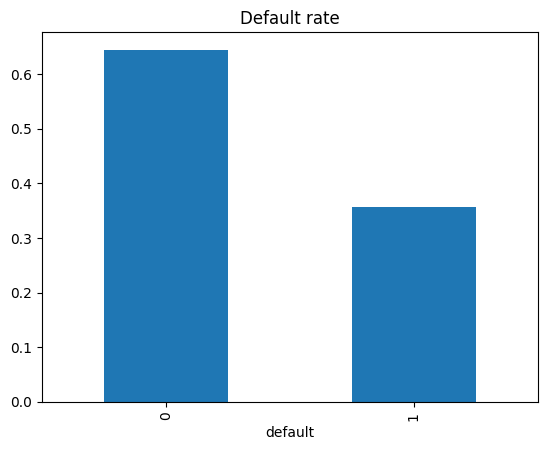

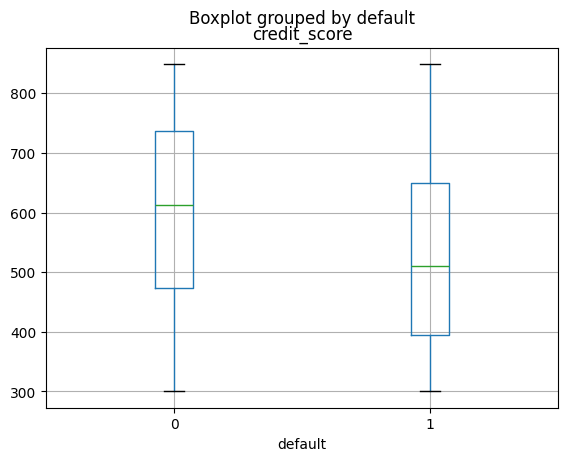

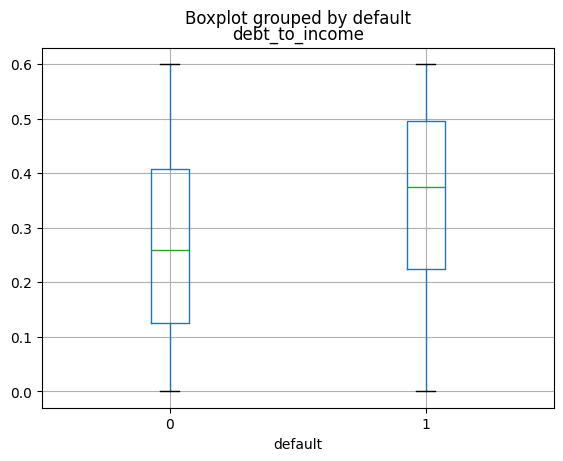

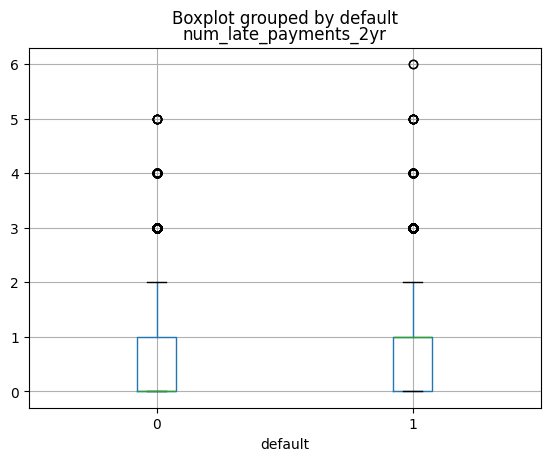

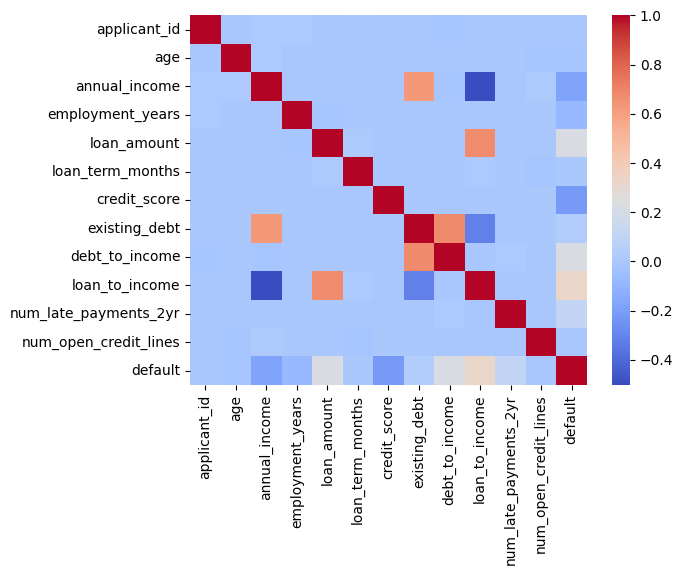

In [3]:
# Class balance — this matters a lot for modeling choices later
df["default"].value_counts(normalize=True).plot(kind="bar", title="Default rate")
plt.show()
# Key relationships to sanity-check
for col in ["credit_score", "debt_to_income", "num_late_payments_2yr"]:
    df.boxplot(column=col, by="default")
plt.show()
# Correlation heatmap of numeric features
import seaborn as sns
numeric_cols = df.select_dtypes("number").columns
sns.heatmap(df[numeric_cols].corr(), annot=False, cmap="coolwarm")
plt.show()


In [4]:
# Feature Engineering and Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

NUMERIC_FEATURES = [
    "age", "annual_income", "employment_years", "loan_amount",
    "loan_term_months", "credit_score", "existing_debt",
    "debt_to_income", "loan_to_income", "num_late_payments_2yr",
    "num_open_credit_lines",
]
CATEGORICAL_FEATURES = ["home_ownership", "loan_purpose"]
def build_preprocessor() -> ColumnTransformer:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, NUMERIC_FEATURES),
        ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
    ])

In [5]:
# Handling class imbalance
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=42)

In [6]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Modeling - Train and compare multiple models
import os
import joblib
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score


def load_data():
    df = pd.read_csv("data/raw/loan_applications.csv")
    X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
    y = df["default"]
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


def build_models():
    models = {
        "logistic_regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "decision_tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced"),
        "random_forest": RandomForestClassifier(n_estimators=400, class_weight="balanced"),
    }
    if XGBClassifier is not None:
        models["xgboost"] = XGBClassifier(
            n_estimators=400,
            max_depth=5,
            learning_rate=0.05,
            scale_pos_weight=4,
            eval_metric="auc",
            random_state=42,
        )
    return models


def main():
    X_train, X_test, y_train, y_test = load_data()
    preprocessor = build_preprocessor()
    results = {}

    for name, clf in build_models().items():
        pipe = Pipeline([("preprocess", preprocessor), ("model", clf)])
        pipe.fit(X_train, y_train)
        proba = pipe.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, proba)
        results[name] = auc
        print(f"{name:20s} ROC-AUC = {auc:.4f}")

    best_name = ""
    best_auc = float("-inf")
    for name, auc in results.items():
        if auc > best_auc:
            best_name = name
            best_auc = auc
    print(f"\nBest model: {best_name}")

    best_model = build_models()[best_name]
    best_pipe = Pipeline([("preprocess", preprocessor), ("model", best_model)])
    calibrated = CalibratedClassifierCV(best_pipe, method="isotonic", cv=5)
    calibrated.fit(X_train, y_train)

    os.makedirs("src/models", exist_ok=True)
    joblib.dump(calibrated, "src/models/credit_risk_model.pkl")
    X_test.assign(y_true=y_test).to_csv("data/raw/test_set.csv", index=False)
    print("Saved calibrated model to src/models/credit_risk_model.pkl")


if __name__ == "__main__":
    main()


logistic_regression  ROC-AUC = 0.7727
decision_tree        ROC-AUC = 0.7423
random_forest        ROC-AUC = 0.7581
xgboost              ROC-AUC = 0.7571

Best model: logistic_regression
Saved calibrated model to src/models/credit_risk_model.pkl


ROC-AUC : 0.7722263899444543
PR-AUC : 0.6708079749579758
              precision    recall  f1-score   support

           0      0.762     0.849     0.803      2577
           1      0.655     0.519     0.579      1423

    accuracy                          0.732      4000
   macro avg      0.709     0.684     0.691      4000
weighted avg      0.724     0.732     0.723      4000

Confusion matrix:
 [[2189  388]
 [ 685  738]]


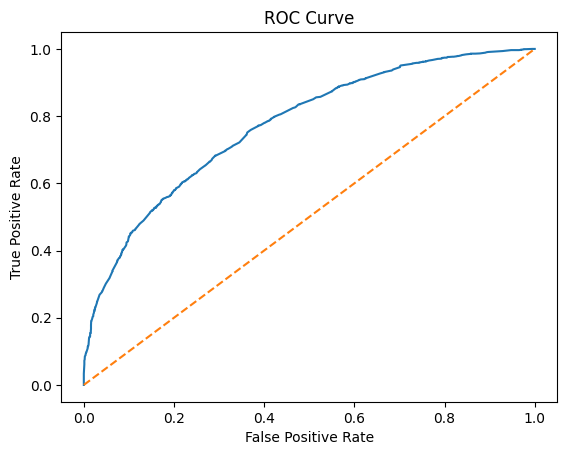

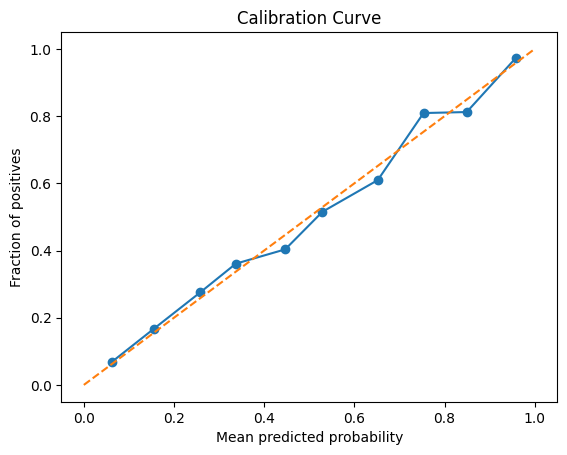

In [8]:
# Evaluation and Interpretation
import joblib
import pandas as pd
from sklearn.metrics import (
roc_auc_score, average_precision_score, precision_recall_curve,
confusion_matrix, classification_report, roc_curve,
)
import matplotlib.pyplot as plt

model = joblib.load("src/models/credit_risk_model.pkl")
test_df = pd.read_csv("data/raw/test_set.csv")
y_true = test_df.pop("y_true")
X_test = test_df
proba = model.predict_proba(X_test)[:, 1]
preds = (proba >= 0.5).astype(int)
print("ROC-AUC :", roc_auc_score(y_true, proba))
print("PR-AUC :", average_precision_score(y_true, proba))
print(classification_report(y_true, preds, digits=3))
print("Confusion matrix:\n", confusion_matrix(y_true, preds))

# ROC curve
fpr, tpr, _ = roc_curve(y_true, proba)
plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve")
plt.savefig("data/raw/roc_curve.png")


# Calibration check
from sklearn.calibration import calibration_curve
prob_true, prob_pred = calibration_curve(y_true, proba, n_bins=10)
plt.figure()
plt.plot(prob_pred, prob_true, marker="o")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("Mean predicted probability"); plt.ylabel("Fraction of positives")
plt.title("Calibration Curve")
plt.savefig("data/raw/calibration_curve.png")

In [9]:
%pip install shap

c:\Users\Rmrdc\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


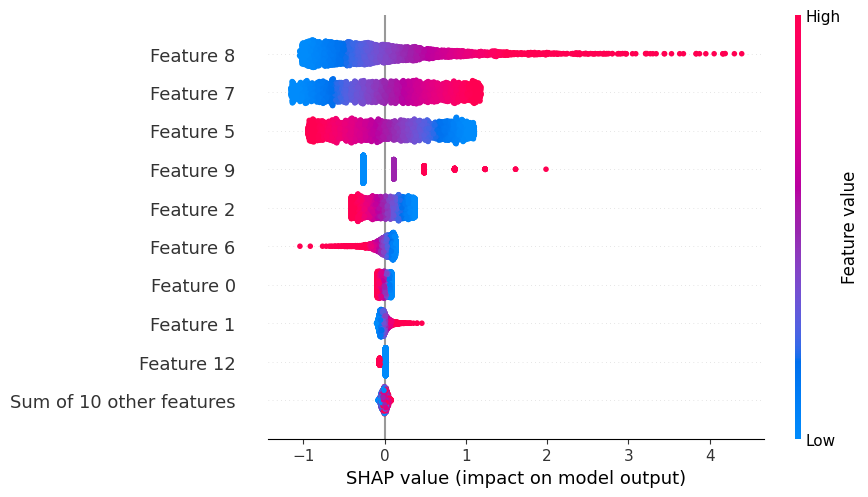

<Figure size 640x480 with 0 Axes>

In [10]:
#Shapley Additive exPlanations (SHAP) for model interpretability
import shap
import joblib
import pandas as pd

model = joblib.load("src/models/credit_risk_model.pkl")
X_test = pd.read_csv("data/raw/test_set.csv").drop(columns=["y_true"])

# Access the underlying fitted estimator inside the calibrated pipeline
base_pipeline = model.calibrated_classifiers_[0].estimator
preprocessor = base_pipeline.named_steps["preprocess"]
tree_model = base_pipeline.named_steps["model"]
X_transformed = preprocessor.transform(X_test)
explainer = shap.Explainer(tree_model, X_transformed)
shap_values = explainer(X_transformed)

shap.plots.beeswarm(shap_values)

import matplotlib.pyplot as plt
plt.savefig("data/raw/shap_summary.png", bbox_inches="tight")